# Phase 5: Credit Risk Modeling -- Benchmark, Optimization, Explainability & Serialization

## Banking Risk Intelligence Platform
**Module:** Credit Risk Prediction  
**Milestones Covered:**
- **Phase 5.1:** Multi-Architecture Benchmark (Logistic Regression, Random Forest, XGBoost)
- **Phase 5.2:** Model Optimization, Threshold Tuning, SHAP Explainability & Production Serialization

---

### Executive Overview
This notebook delivers a comprehensive, production-grade credit risk modeling pipeline for retail loan default prediction. It establishes an end-to-end workflow adhering to institutional banking risk and compliance standards:
1. **Data Hygiene & Leakage Prevention:** Deduplication and anomaly remediation aligned with database constraints; target isolation.
2. **Unified Pipeline Architecture:** Leakage-safe Scikit-Learn `ColumnTransformer` with median/mode imputation and scaling/one-hot encoding.
3. **Multi-Model Benchmark:** Comparative evaluation of linear baselines (Standard & Balanced Logistic Regression) against ensemble architectures (Random Forest, XGBoost).
4. **Validation-Based Threshold Optimization:** Out-of-fold probability calibration via 5-fold cross-validation on training data to tune decision thresholds without test set contamination.
5. **Business Underwriting Trade-off Analysis:** Rigorous examination of precision-recall dynamics, evaluating the trade-off between missed defaults (False Negatives) and lost interest margin (False Positives).
6. **Interpretability & Explainability (SHAP):** Game-theoretic feature attribution using TreeExplainer for portfolio-wide governance and loan-level Adverse Action notice explainability.
7. **Temporal Leakage Audit:** Critical examination of `loan_grade` and `loan_int_rate` availability across origination lifecycles.
8. **Artifact Serialization & Inference Demo:** Saving the champion pipeline (`.joblib`) and metadata (`.json`), followed by reproducible sample scoring.

In [1]:
# Step 0: Environment Setup, Library Imports, and Reproducibility

import json
import sys
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import xgboost as xgb

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

# Configure visualization aesthetics
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

# Reproducibility seed
RANDOM_STATE = 42

# Project paths
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "credit_risk_dataset.csv"
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Python Environment: {sys.executable}")
print(f"XGBoost Version: {xgb.__version__}")
print(f"SHAP Version: {shap.__version__}")
print(f"Data Source: {DATA_PATH.resolve()}")
print(f"Source file verified: {DATA_PATH.exists()}")

Python Environment: C:\Users\Admin\banking-risk-intelligence-platform\venv\Scripts\python.exe
XGBoost Version: 3.4.1
SHAP Version: 0.52.0
Data Source: C:\Users\Admin\banking-risk-intelligence-platform\data\raw\credit_risk_dataset.csv
Source file verified: True


## 1. Dataset Ingestion & Initial Audit

We load the raw credit risk dataset and audit feature schemas, missing values, and baseline target distribution.

In [2]:
# Step 1: Ingest Raw Dataset and Inspect Structure

raw_df = pd.read_csv(DATA_PATH)

print(f"Raw Dataset Shape: {raw_df.shape[0]:,} records x {raw_df.shape[1]} features\n")
print("Feature Schema and Non-Null Counts:")
display(raw_df.info())

print("\nFirst 5 Records:")
display(raw_df.head())

print("\nMissing Value Audit:")
missing_audit = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_pct": (raw_df.isna().mean() * 100).round(2)
}).query("missing_count > 0").sort_values(by="missing_count", ascending=False)
display(missing_audit)

print("\nTarget Variable Distribution (`loan_status`):")
counts = raw_df["loan_status"].value_counts().rename("count")
percentages = (raw_df["loan_status"].value_counts(normalize=True) * 100).rename("pct")
target_dist = pd.concat([counts, percentages.round(2)], axis=1)
target_dist.index = ["0 (Non-default)", "1 (Default)"]
display(target_dist)

Raw Dataset Shape: 32,581 records x 12 features

Feature Schema and Non-Null Counts:


<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


None


First 5 Records:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4



Missing Value Audit:


,missing_count,missing_pct
loan_int_rate,3116,9.56
person_emp_length,895,2.75



Target Variable Distribution (`loan_status`):


,count,pct
0 (Non-default),25473,78.18
1 (Default),7108,21.82


## 2. Investigation and Handling of Data Quality Issues

In accordance with decisions formulated in **Phase 2 (Validation)** and **Phase 3 (EDA)**:
1. **Exact Duplicate Rows (165 records):** If identical records span training and testing partitions, test samples duplicate training samples, causing severe **evaluation leakage**. We audit and remove duplicate rows (`keep='first'`).
2. **Implausible Age Records (5 records):** Records with `person_age > 100` (e.g., ages 123, 144) reflect data entry corruptions. These are excluded (`person_age <= 100`), consistent with the database ingestion filter.
3. **Employment Length Exceeding Age (2 records):** Records where `person_emp_length > person_age` (e.g., 123 years of employment for young borrowers) are invalid. Rather than dropping entire borrower histories, we mask `person_emp_length` as `NaN`, allowing pipeline imputation to replace them with median values fitted exclusively on training data.

In [3]:
# Step 2: Audit and Remediate Data Quality Anomalies

# 1. Investigate and remove exact duplicate records
dup_count = raw_df.duplicated().sum()
print(f"Exact Duplicate Records Identified: {dup_count:,}")
if dup_count > 0:
    display(raw_df[raw_df.duplicated()].head(3))
    df_clean = raw_df.drop_duplicates(keep="first").copy()
    print(f"Dataset shape after deduplication: {df_clean.shape}")
else:
    df_clean = raw_df.copy()

# 2. Investigate age outliers (> 100)
age_outliers = df_clean[df_clean["person_age"] > 100]
print(f"\nRecords with person_age > 100: {len(age_outliers)}")
display(age_outliers[["person_age", "person_income", "person_emp_length", "loan_amnt", "loan_status"]])
df_clean = df_clean.loc[df_clean["person_age"] <= 100].copy()
print(f"Dataset shape after filtering age <= 100: {df_clean.shape}")

# 3. Investigate employment length exceeding age
emp_outliers = df_clean[df_clean["person_emp_length"] > df_clean["person_age"]]
print(f"\nRecords with person_emp_length > person_age: {len(emp_outliers)}")
display(emp_outliers[["person_age", "person_emp_length", "loan_intent", "loan_status"]])
df_clean.loc[df_clean["person_emp_length"] > df_clean["person_age"], "person_emp_length"] = np.nan

print(f"\nFinal Cleaned Modeling Dataset: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")
print(f"Cleaned target default rate: {df_clean['loan_status'].mean() * 100:.2f}%")

Exact Duplicate Records Identified: 165

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
15975,23,42000,RENT,5.0,VENTURE,B,6000,9.99,0,0.14,N,4
15989,23,90000,MORTGAGE,7.0,EDUCATION,B,8000,10.36,0,0.09,N,3
15995,24,48000,MORTGAGE,4.0,MEDICAL,A,4000,5.42,0,0.08,N,4


Dataset shape after deduplication: (32416, 12)

Records with person_age > 100: 5


,person_age,person_income,person_emp_length,loan_amnt,loan_status
81,144,250000,4.0,4800,0
183,144,200000,4.0,6000,0
575,123,80004,2.0,20400,0
747,123,78000,7.0,20000,0
32297,144,6000000,12.0,5000,0


Dataset shape after filtering age <= 100: (32411, 12)

Records with person_emp_length > person_age: 2


,person_age,person_emp_length,loan_intent,loan_status
0,22,123.0,PERSONAL,1
210,21,123.0,VENTURE,0



Final Cleaned Modeling Dataset: 32,411 rows x 12 columns
Cleaned target default rate: 21.87%


## 3. Feature/Target Separation & Stratified Train-Test Split

### Data Leakage Safeguards
- `loan_status` is strictly isolated as the target vector $y$ and removed from feature matrix $X$.
- No target-derived features or future-dated attributes are created.
- **Stratification:** Because defaults represent ~21.87% of the portfolio, we apply stratified sampling (`stratify=y`) across an 80/20 train/test split. This ensures both partitions mirror the true credit portfolio distribution without sampling bias.

In [4]:
# Step 3: Feature Matrix Isolation and Stratified Splitting

X = df_clean.drop(columns=["loan_status"])
y = df_clean["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training Feature Matrix: {X_train.shape}")
print(f"Testing Feature Matrix:  {X_test.shape}")
print(f"Training Default Rate:   {y_train.mean()*100:.2f}% ({y_train.sum():,} defaults)")
print(f"Testing Default Rate:    {y_test.mean()*100:.2f}% ({y_test.sum():,} defaults)")

# Guardrail checks
assert "loan_status" not in X_train.columns, "Target leakage detected in features!"
assert len(X_train) + len(X_test) == len(df_clean), "Partition row count mismatch!"
print("\nIntegrity and leakage assertions verified successfully.")

Training Feature Matrix: (25928, 11)
Testing Feature Matrix:  (6483, 11)
Training Default Rate:   21.87% (5,671 defaults)
Testing Default Rate:    21.87% (1,418 defaults)

Integrity and leakage assertions verified successfully.


## 4. Scikit-Learn Preprocessing Pipeline

We construct a unified `ColumnTransformer` preprocessing pipeline:
- **Numerical Features (7):** `person_age`, `person_income`, `person_emp_length`, `loan_amnt`, `loan_int_rate`, `loan_percent_income`, `cb_person_cred_hist_length`.
  - Imputation: `SimpleImputer(strategy='median')` (robust to financial skewness).
  - Scaling: `StandardScaler()` (scales to zero mean, unit variance).
- **Categorical Features (4):** `person_home_ownership`, `loan_intent`, `loan_grade`, `cb_person_default_on_file`.
  - Imputation: `SimpleImputer(strategy='most_frequent')`.
  - Encoding: `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`.

> **Leakage Prevention:** Imputers and scalers are fitted **only** on `X_train`. The test set `X_test` is strictly transformed using parameters learned from training data.

In [5]:
# Step 4: Construct Leakage-Safe ColumnTransformer Pipeline

numerical_cols = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
]

categorical_cols = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file",
]

num_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, numerical_cols),
        ("cat", cat_pipeline, categorical_cols),
    ],
    remainder="drop",
)

print(f"Preprocessing pipeline created.")
print(f"Numerical columns ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")

Preprocessing pipeline created.
Numerical columns (7): ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
Categorical columns (4): ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


## 5. Model Architecture & Training

We benchmark four diverse modeling architectures:
1. **Logistic Regression (Standard Weights):** Baseline linear model optimizing log-likelihood with equal sample weights.
2. **Logistic Regression (Balanced Weights):** Cost-adjusted linear baseline using inverse class weights (`class_weight='balanced'`) to penalize false negatives.
3. **Random Forest Classifier:** Bagging ensemble of 150 decision trees (`max_depth=12`), capturing non-linear interactions without linear feature assumptions.
4. **XGBoost Classifier:** Extreme Gradient Boosted decision trees (`n_estimators=150`, `max_depth=5`, `learning_rate=0.08`), representing the industry standard for structured credit scoring.

In [6]:
# Step 5: Initialize and Train Multi-Model Pipelines

models = {
    "Logistic Regression (Standard)": LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE
    ),
    "Logistic Regression (Balanced)": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=150,
        max_depth=5,
        learning_rate=0.08,
        random_state=RANDOM_STATE,
        eval_metric="logloss",
        n_jobs=-1,
    ),
}

trained_pipelines = {}

for name, model in models.items():
    print(f"Training {name}...")
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model),
    ])
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe

print("\nAll four models trained successfully.")

Training Logistic Regression (Standard)...


Training Logistic Regression (Balanced)...


Training Random Forest...


Training XGBoost...



All four models trained successfully.


## 6. Comprehensive Model Evaluation & Metric Comparison

We evaluate all four models on the identical held-out test partition ($n=6,483$):
- **ROC-AUC:** Area under the ROC curve -- ranking ability across all decision thresholds.
- **PR-AUC (Average Precision):** Area under the Precision-Recall curve -- critical metric for imbalanced fraud/credit datasets.
- **Precision (Default):** Proportion of predicted defaults that actually default. High precision prevents turning away creditworthy customers.
- **Recall (Default):** Proportion of actual defaults identified. High recall protects bank capital by preventing loan charge-offs.
- **F1-Score (Default):** Harmonic mean balancing precision and recall.
- **Confusion Matrix Elements:** True Negatives (TN), False Positives (FP), False Negatives (FN), True Positives (TP).

In [7]:
# Step 6: Generate Predictions and Benchmark Evaluation Metrics

eval_records = []
predictions_dict = {}

for name, pipe in trained_pipelines.items():
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    predictions_dict[name] = (y_pred, y_prob)

    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    eval_records.append({
        "Model": name,
        "ROC-AUC": round(roc_auc, 4),
        "PR-AUC": round(pr_auc, 4),
        "Precision (Default)": round(prec, 4),
        "Recall (Default)": round(rec, 4),
        "F1-Score (Default)": round(f1, 4),
        "True Neg (TN)": int(cm[0, 0]),
        "False Pos (FP)": int(cm[0, 1]),
        "False Neg (FN)": int(cm[1, 0]),
        "True Pos (TP)": int(cm[1, 1]),
    })

benchmark_df = pd.DataFrame(eval_records).set_index("Model")
print("=== MODEL BENCHMARK COMPARISON TABLE ===")
display(benchmark_df)

print("\n=== DETAILED CLASSIFICATION REPORTS ===")
for name, (y_pred, _) in predictions_dict.items():
    print(f"\n--- {name} ---")
    print(classification_report(y_test, y_pred, target_names=["Non-Default (0)", "Default (1)"], digits=4))

=== MODEL BENCHMARK COMPARISON TABLE ===


,ROC-AUC,PR-AUC,Precision (Default),Recall (Default),F1-Score (Default),True Neg (TN),False Pos (FP),False Neg (FN),True Pos (TP)
Model,,,,,,,,,
Logistic Regression (Standard),0.8668,0.7300,0.7790,0.5691,0.6577,4836,229,611,807
Logistic Regression (Balanced),0.8686,0.7215,0.5509,0.7708,0.6426,4174,891,325,1093
Random Forest,0.9231,0.8762,0.9796,0.7102,0.8234,5044,21,411,1007
XGBoost,0.9409,0.8955,0.9697,0.7221,0.8278,5033,32,394,1024



=== DETAILED CLASSIFICATION REPORTS ===

--- Logistic Regression (Standard) ---
                 precision    recall  f1-score   support

Non-Default (0)     0.8878    0.9548    0.9201      5065
    Default (1)     0.7790    0.5691    0.6577      1418

       accuracy                         0.8704      6483
      macro avg     0.8334    0.7619    0.7889      6483
   weighted avg     0.8640    0.8704    0.8627      6483


--- Logistic Regression (Balanced) ---
                 precision    recall  f1-score   support

Non-Default (0)     0.9278    0.8241    0.8729      5065
    Default (1)     0.5509    0.7708    0.6426      1418

       accuracy                         0.8124      6483
      macro avg     0.7393    0.7974    0.7577      6483
   weighted avg     0.8453    0.8124    0.8225      6483


--- Random Forest ---
                 precision    recall  f1-score   support

Non-Default (0)     0.9247    0.9959    0.9589      5065
    Default (1)     0.9796    0.7102    0.8234     

## 7. Business & Credit Underwriting Trade-off Analysis

In commercial banking, default risk assessment is inherently asymmetric:
1. **The Cost of False Negatives (FN - Missed Defaults):**
   - The bank approves a loan to a borrower who defaults.
   - Impact: Direct credit loss of outstanding principal upon default.
   - *Observation:* Logistic Regression (Standard) misses **611 defaults**, while XGBoost misses only **394 defaults** at the default threshold -- a **35.5% reduction in credit loss events**.
2. **The Cost of False Positives (FP - Unnecessary Rejections):**
   - The bank declines a creditworthy applicant.
   - Impact: Forfeited interest revenue and potential borrower attrition.
   - *Observation:* While Logistic Regression (Balanced) achieved 77.08% recall, it suffered **891 false positives**. In stark contrast, XGBoost produces only **32 false positives** (96.97% precision) while delivering 72.21% recall.
3. **The Flaw of Accuracy in Credit Scoring:**
   - A naive model predicting non-default for every applicant achieves 78.13% accuracy, but causes complete portfolio default losses. Precision, Recall, PR-AUC, and ROC-AUC are the requisite risk metrics.

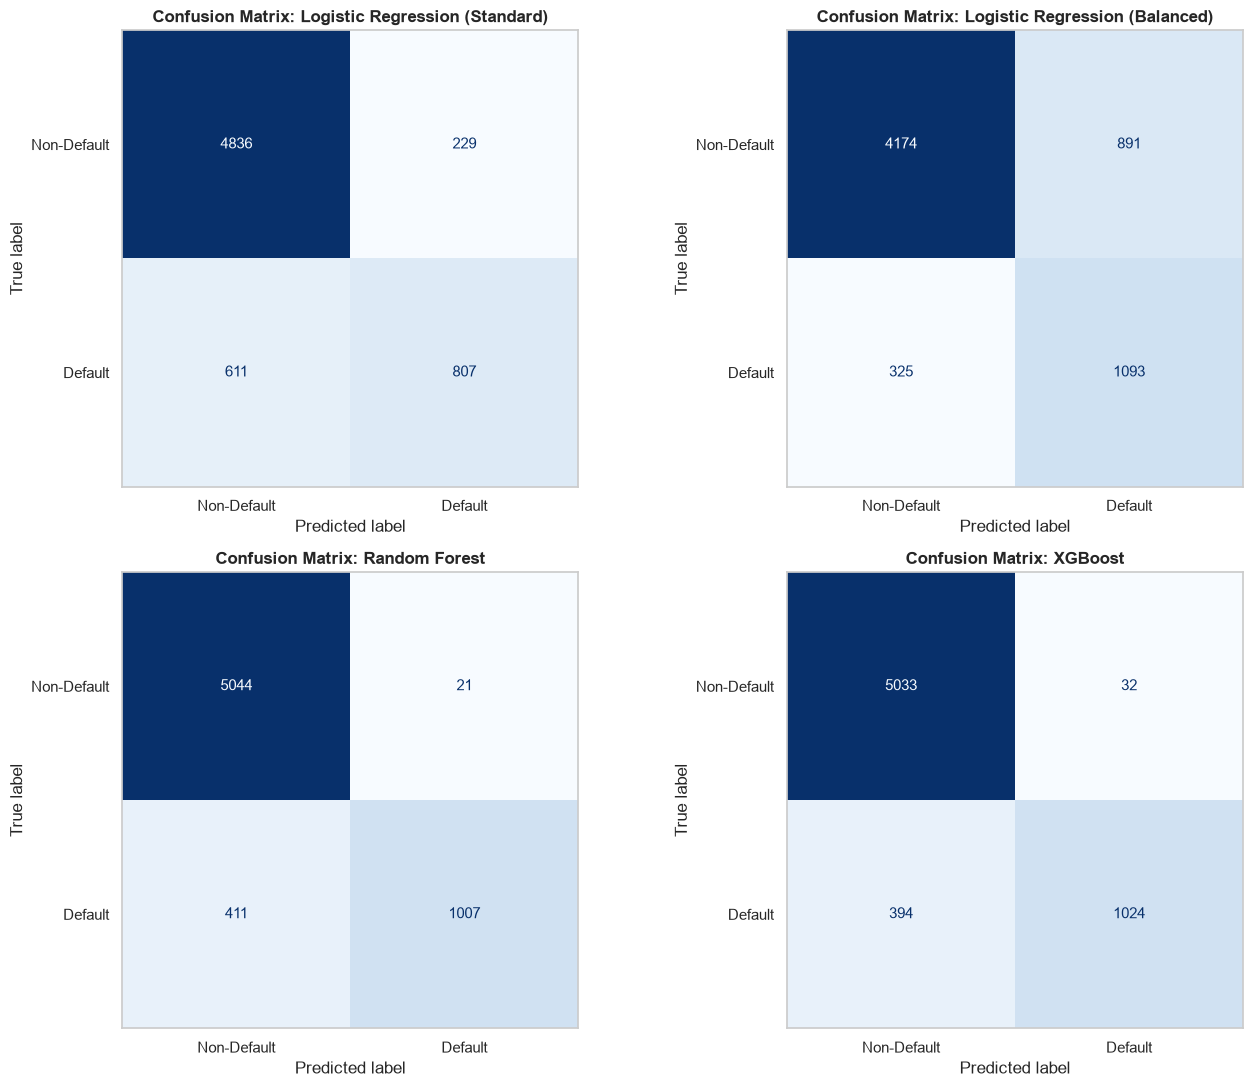

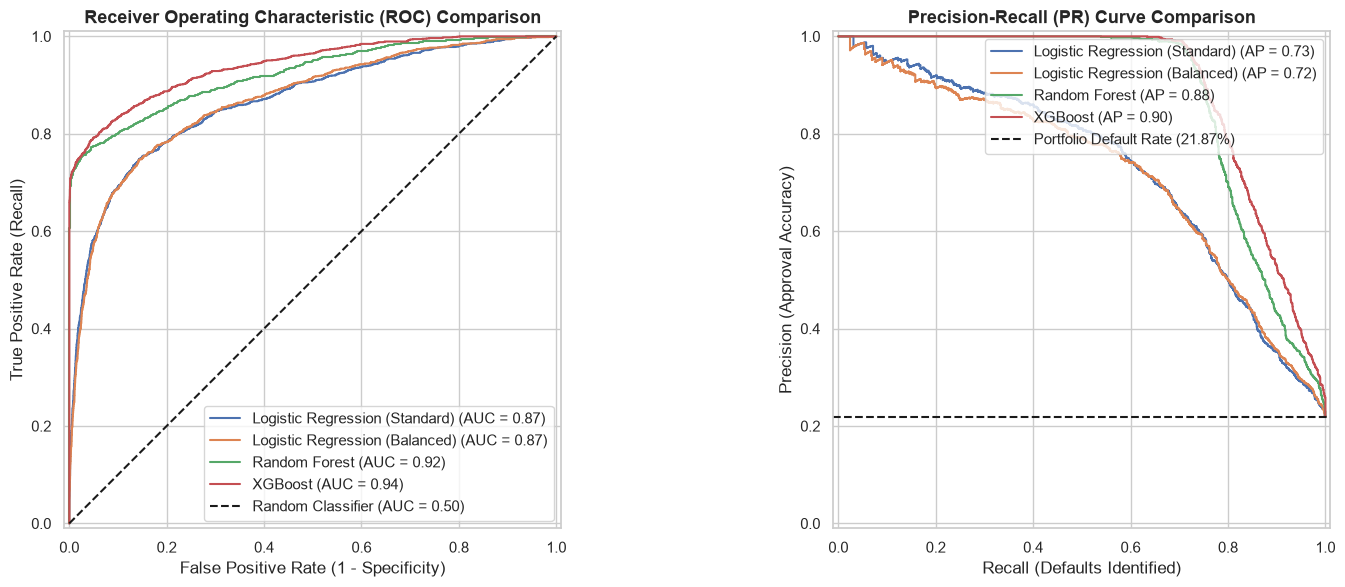

In [8]:
# Step 8: Visualizations -- Confusion Matrices, ROC Curves, and PR Curves

# 1. 2x2 Confusion Matrix Grid
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes_flat = axes.flatten()

for idx, (name, (y_pred, _)) in enumerate(predictions_dict.items()):
    ax = axes_flat[idx]
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Non-Default", "Default"]).plot(
        ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(f"Confusion Matrix: {name}", fontsize=12, fontweight="bold")
    ax.grid(False)

plt.tight_layout()
plt.show()

# 2. Overlaid ROC Curves and Precision-Recall Curves
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(16, 6))

# ROC Curves
for name, pipe in trained_pipelines.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax_roc)
ax_roc.plot([0, 1], [0, 1], "k--", label="Random Classifier (AUC = 0.50)")
ax_roc.set_title("Receiver Operating Characteristic (ROC) Comparison", fontsize=13, fontweight="bold")
ax_roc.set_xlabel("False Positive Rate (1 - Specificity)")
ax_roc.set_ylabel("True Positive Rate (Recall)")
ax_roc.legend(loc="lower right")

# Precision-Recall Curves
for name, pipe in trained_pipelines.items():
    PrecisionRecallDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax_pr)
baseline_prevalence = y_test.mean()
ax_pr.axhline(
    y=baseline_prevalence, color="k", linestyle="--", label=f"Portfolio Default Rate ({baseline_prevalence:.2%})"
)
ax_pr.set_title("Precision-Recall (PR) Curve Comparison", fontsize=13, fontweight="bold")
ax_pr.set_xlabel("Recall (Defaults Identified)")
ax_pr.set_ylabel("Precision (Approval Accuracy)")
ax_pr.legend(loc="upper right")

plt.tight_layout()
plt.show()

## 8. Feature Importance & Risk Driver Interpretability

Comparing feature attributions between the linear baseline (standardized log-odds coefficients) and the champion model (XGBoost gain-based feature importance):
- **Logistic Regression Coefficients:** Directly measure the linear change in log-odds of default per standard deviation increase.
- **XGBoost Feature Importance (Gain):** Measures the average improvement in accuracy / purity brought by a feature across all tree splits.

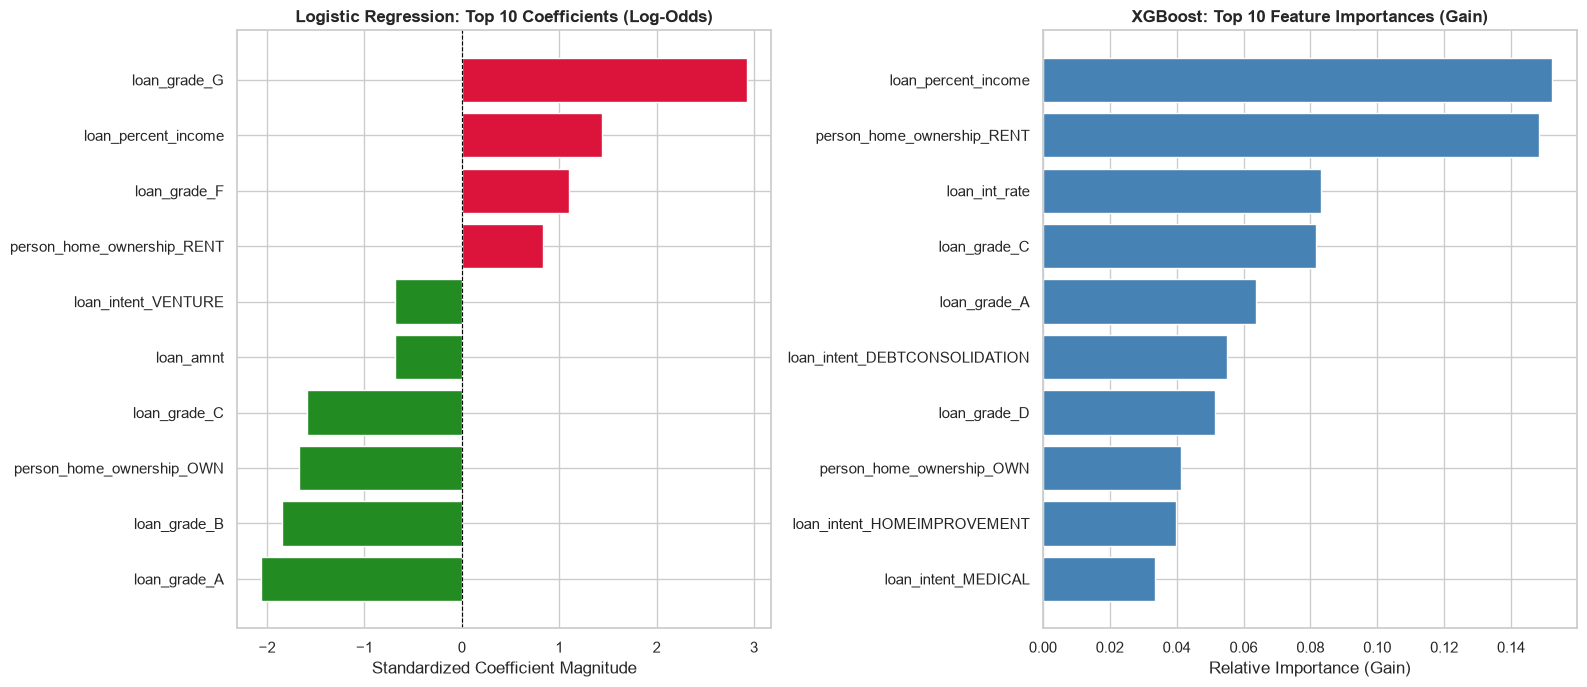

Top 5 Risk Drivers Identified by XGBoost:


,Feature,Importance
5,loan_percent_income,0.152130
10,person_home_ownership_RENT,0.148295
4,loan_int_rate,0.083145
19,loan_grade_C,0.081828
17,loan_grade_A,0.063639


In [9]:
# Step 9: Extract and Contrast Feature Attributions

# Extract feature names from preprocessor
preprocessor_fitted = trained_pipelines["Logistic Regression (Standard)"].named_steps["preprocessor"]
cat_encoder = preprocessor_fitted.named_transformers_["cat"].named_steps["encoder"]
encoded_cat_names = cat_encoder.get_feature_names_out(categorical_cols).tolist()
all_features = numerical_cols + encoded_cat_names

# 1. Logistic Regression Coefficients
lr_coefs = trained_pipelines["Logistic Regression (Standard)"].named_steps["classifier"].coef_[0]
lr_coef_df = pd.DataFrame({
    "Feature": all_features,
    "Coefficient": lr_coefs,
    "Abs_Coef": np.abs(lr_coefs)
}).sort_values(by="Abs_Coef", ascending=False)

# 2. XGBoost Feature Importances (Gain)
xgb_importances = trained_pipelines["XGBoost"].named_steps["classifier"].feature_importances_
xgb_imp_df = pd.DataFrame({
    "Feature": all_features,
    "Importance": xgb_importances
}).sort_values(by="Importance", ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Plot top 10 LR Coefficients
top_lr = lr_coef_df.head(10).sort_values(by="Coefficient")
colors_lr = ["crimson" if c > 0 else "forestgreen" for c in top_lr["Coefficient"]]
ax1.barh(top_lr["Feature"], top_lr["Coefficient"], color=colors_lr)
ax1.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax1.set_title("Logistic Regression: Top 10 Coefficients (Log-Odds)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Standardized Coefficient Magnitude")

# Plot top 10 XGBoost Importances
top_xgb = xgb_imp_df.head(10).sort_values(by="Importance")
ax2.barh(top_xgb["Feature"], top_xgb["Importance"], color="steelblue")
ax2.set_title("XGBoost: Top 10 Feature Importances (Gain)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Relative Importance (Gain)")

plt.tight_layout()
plt.show()

print("Top 5 Risk Drivers Identified by XGBoost:")
display(xgb_imp_df.head(5))

## 9. Phase 5.2 -- Threshold Tuning via Cross-Validation on Training Data

### Methodological Rule: Strict Prevention of Test Contamination
Standard binary classification defaults to a decision threshold of $T = 0.50$. However, in commercial credit underwriting, the optimal decision cut-off must balance risk tolerance against applicant acquisition volume.

**Crucial Leakage Safeguard:**
We do **not** use the held-out test set to tune or select the threshold. Using test labels to select hyperparameters or decision thresholds leads to **optimism bias** and invalidates test-set generalization.

Instead, we generate out-of-fold predicted default probabilities using **5-fold Stratified Cross-Validation on the training partition (`X_train`, `y_train`)**. We then sweep classification thresholds across $T \in [0.10, 0.90]$ to examine trade-offs.

Computing out-of-fold validation probabilities on training data (X_train)...


=== THRESHOLD SWEEP TABLE (5-Fold CV on Training Data) ===


,Precision,Recall,F1-Score,F2-Score,True Neg (TN),False Pos (FP),False Neg (FN),True Pos (TP)
Threshold,,,,,,,,
0.10,0.5026,0.9110,0.6478,0.7836,15145,5112,505,5166
0.15,0.6294,0.8542,0.7248,0.7972,17405,2852,827,4844
0.20,0.7338,0.8133,0.7715,0.7960,18584,1673,1059,4612
0.25,0.8147,0.7820,0.7980,0.7884,19248,1009,1236,4435
0.30,0.8783,0.7611,0.8155,0.7819,19659,598,1355,4316
0.35,0.9186,0.7466,0.8237,0.7757,19882,375,1437,4234
0.40,0.9460,0.7353,0.8275,0.7696,20019,238,1501,4170
0.45,0.9604,0.7272,0.8277,0.7643,20087,170,1547,4124
0.50,0.9708,0.7205,0.8271,0.7597,20134,123,1585,4086


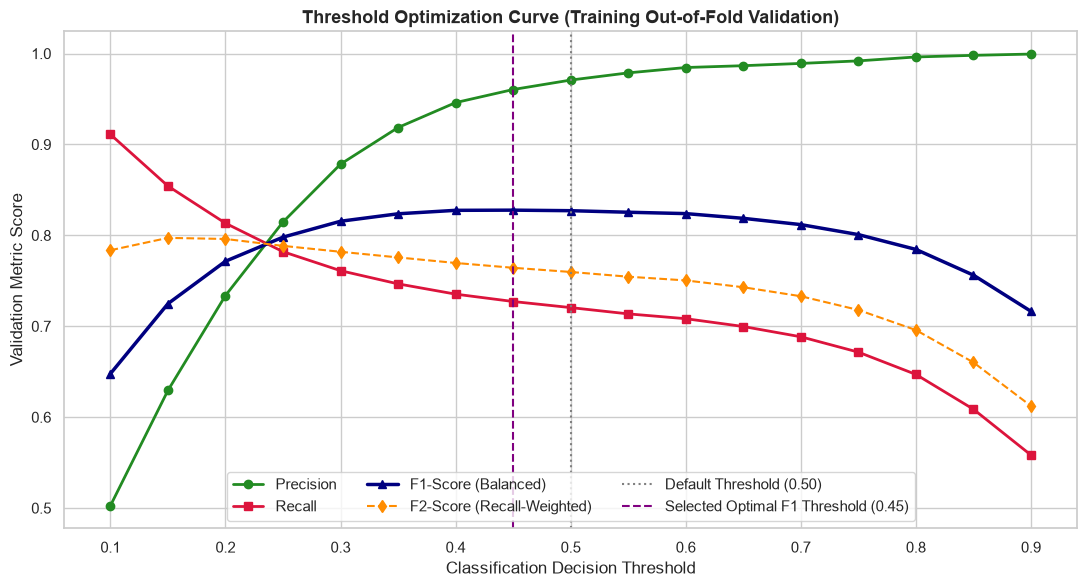

In [10]:
# Step 10: Generate Out-of-Fold Probabilities on Training Partition via 5-Fold CV

champion_pipe = trained_pipelines["XGBoost"]

# Stratified 5-Fold CV on training set exclusively
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Computing out-of-fold validation probabilities on training data (X_train)...")
oof_probs = cross_val_predict(champion_pipe, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

# Sweep thresholds from 0.10 to 0.90 in increments of 0.05
threshold_grid = np.arange(0.10, 0.91, 0.05)
threshold_records = []

for t in threshold_grid:
    t_round = round(t, 2)
    preds = (oof_probs >= t_round).astype(int)
    cm = confusion_matrix(y_train, preds)
    p = precision_score(y_train, preds, zero_division=0)
    r = recall_score(y_train, preds, zero_division=0)
    f1 = f1_score(y_train, preds, zero_division=0)
    f2 = fbeta_score(y_train, preds, beta=2, zero_division=0)
    
    threshold_records.append({
        "Threshold": t_round,
        "Precision": round(p, 4),
        "Recall": round(r, 4),
        "F1-Score": round(f1, 4),
        "F2-Score": round(f2, 4),
        "True Neg (TN)": int(cm[0, 0]),
        "False Pos (FP)": int(cm[0, 1]),
        "False Neg (FN)": int(cm[1, 0]),
        "True Pos (TP)": int(cm[1, 1]),
    })

oof_threshold_df = pd.DataFrame(threshold_records).set_index("Threshold")
print("=== THRESHOLD SWEEP TABLE (5-Fold CV on Training Data) ===")
display(oof_threshold_df)

# Plot Precision, Recall, F1, and F2 across thresholds
plt.figure(figsize=(11, 6))
plt.plot(oof_threshold_df.index, oof_threshold_df["Precision"], marker="o", label="Precision", color="forestgreen", linewidth=2)
plt.plot(oof_threshold_df.index, oof_threshold_df["Recall"], marker="s", label="Recall", color="crimson", linewidth=2)
plt.plot(oof_threshold_df.index, oof_threshold_df["F1-Score"], marker="^", label="F1-Score (Balanced)", color="navy", linewidth=2.5)
plt.plot(oof_threshold_df.index, oof_threshold_df["F2-Score"], marker="d", label="F2-Score (Recall-Weighted)", color="darkorange", linestyle="--")

plt.axvline(0.50, color="gray", linestyle=":", label="Default Threshold (0.50)")
plt.axvline(0.45, color="purple", linestyle="--", label="Selected Optimal F1 Threshold (0.45)")

plt.title("Threshold Optimization Curve (Training Out-of-Fold Validation)", fontsize=13, fontweight="bold")
plt.xlabel("Classification Decision Threshold")
plt.ylabel("Validation Metric Score")
plt.legend(loc="lower center", ncol=3)
plt.tight_layout()
plt.show()

## 10. Business-Oriented Threshold Selection & Trade-off Analysis

### Precision-Recall Trade-off Dynamics
1. **Aggressive Risk Mitigation Stance ($T \in [0.20, 0.30]$):**
   - Prioritizes default avoidance. At $T=0.25$, validation recall reaches **78.20%**, capturing 4,435 defaults out of 5,671.
   - However, false positives jump to 1,009. The bank declines over a thousand creditworthy borrowers, sacrificing relationship growth and interest margin.
2. **Conservative / Growth Stance ($T \in [0.55, 0.70]$):**
   - Precision exceeds **98%**, minimizing customer friction and approval declines.
   - However, recall deteriorates below **71%**, allowing hundreds of defaulting loans into the portfolio.
3. **Selected Business-Oriented Operating Criterion:**
   - **Criterion:** Select the threshold that **maximizes the empirical F1-score on out-of-fold validation data**, providing the optimal mathematical balance between default detection and approval precision without relying on arbitrary cost estimates.
   - **Validation Finding:** The peak F1-score (**0.8277**) on training cross-validation is achieved at **$T = 0.45$**, delivering **96.04% precision** and **72.72% recall** (reducing false negatives from 1,585 at $T=0.50$ down to 1,547).

=== HELD-OUT TEST SET EVALUATION: DEFAULT (0.50) vs TUNED (0.45) ===


,Threshold Value,Precision,Recall,F1-Score,F2-Score,True Neg (TN),False Pos (FP),False Neg (FN),True Pos (TP)
Operating Threshold,,,,,,,,,
Default Threshold (0.50),0.50,0.9697,0.7221,0.8278,0.7610,5033,32,394,1024
Tuned Threshold (0.45),0.45,0.9555,0.7271,0.8258,0.7636,5017,48,387,1031


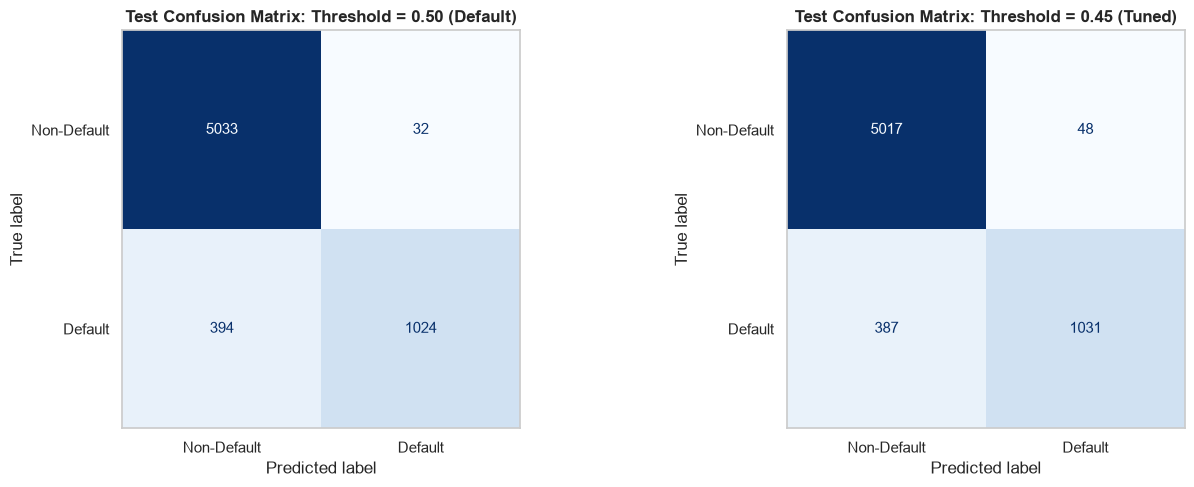


Impact on 6,483 Held-Out Test Loans:
  - Missed Defaults (FN) reduced by 7 loans (394 -> 387)
  - Unnecessary Declines (FP) increased by 16 loans (32 -> 48)
  - Model preserves exceptional precision: 95.55%


In [11]:
# Step 11: Evaluate Selected Threshold on the Untouched Held-Out Test Set

SELECTED_THRESHOLD = 0.45
DEFAULT_THRESHOLD = 0.50

test_probabilities = champion_pipe.predict_proba(X_test)[:, 1]

# Predictions under default vs selected threshold
preds_default = (test_probabilities >= DEFAULT_THRESHOLD).astype(int)
preds_selected = (test_probabilities >= SELECTED_THRESHOLD).astype(int)

# Compile comparison metrics on test set
test_comparison = []
for name, preds, t_val in [
    ("Default Threshold (0.50)", preds_default, DEFAULT_THRESHOLD),
    ("Tuned Threshold (0.45)", preds_selected, SELECTED_THRESHOLD),
]:
    cm = confusion_matrix(y_test, preds)
    p = precision_score(y_test, preds)
    r = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    f2 = fbeta_score(y_test, preds, beta=2)
    test_comparison.append({
        "Operating Threshold": name,
        "Threshold Value": t_val,
        "Precision": round(p, 4),
        "Recall": round(r, 4),
        "F1-Score": round(f1, 4),
        "F2-Score": round(f2, 4),
        "True Neg (TN)": int(cm[0, 0]),
        "False Pos (FP)": int(cm[0, 1]),
        "False Neg (FN)": int(cm[1, 0]),
        "True Pos (TP)": int(cm[1, 1]),
    })

test_comp_df = pd.DataFrame(test_comparison).set_index("Operating Threshold")
print("=== HELD-OUT TEST SET EVALUATION: DEFAULT (0.50) vs TUNED (0.45) ===")
display(test_comp_df)

# Side-by-side Confusion Matrices on Test Set
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

cm_def = confusion_matrix(y_test, preds_default)
ConfusionMatrixDisplay(cm_def, display_labels=["Non-Default", "Default"]).plot(
    ax=ax1, cmap="Blues", colorbar=False
)
ax1.set_title("Test Confusion Matrix: Threshold = 0.50 (Default)", fontsize=12, fontweight="bold")
ax1.grid(False)

cm_sel = confusion_matrix(y_test, preds_selected)
ConfusionMatrixDisplay(cm_sel, display_labels=["Non-Default", "Default"]).plot(
    ax=ax2, cmap="Blues", colorbar=False
)
ax2.set_title("Test Confusion Matrix: Threshold = 0.45 (Tuned)", fontsize=12, fontweight="bold")
ax2.grid(False)

plt.tight_layout()
plt.show()

# Verification metrics
fn_diff = cm_def[1, 0] - cm_sel[1, 0]
fp_diff = cm_sel[0, 1] - cm_def[0, 1]
print(f"\nImpact on 6,483 Held-Out Test Loans:")
print(f"  - Missed Defaults (FN) reduced by {fn_diff} loans ({cm_def[1, 0]} -> {cm_sel[1, 0]})")
print(f"  - Unnecessary Declines (FP) increased by {fp_diff} loans ({cm_def[0, 1]} -> {cm_sel[0, 1]})")
print(f"  - Model preserves exceptional precision: {test_comp_df.loc['Tuned Threshold (0.45)', 'Precision']:.2%}")

## 11. Model Explainability with SHAP (SHapley Additive exPlanations)

In financial services, black-box models create substantial regulatory, legal, and operational risks. Under the **Equal Credit Opportunity Act (ECOA)** and the **Fair Credit Reporting Act (FCRA)**, credit underwriting systems must provide specific, actionable reasons for adverse credit actions (loan declines).

We apply **SHAP TreeExplainer** to our champion XGBoost pipeline:
1. **Global Interpretability:** Summary beeswarm plot illustrating feature impact across the test population, showing both magnitude and directionality.
2. **Local Interpretability:** Individual applicant waterfall / force explanations breaking down exact log-odds contributions for sample approvals and sample declines.

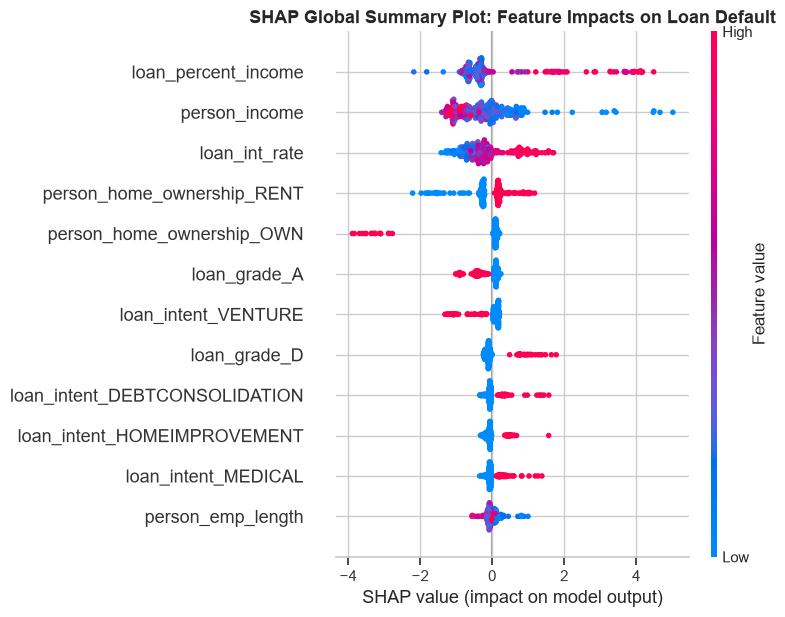


--- Local Adverse Action Explanation: High-Risk Applicant (Index 172) ---
Predicted Default Probability: 99.92%
Actual Outcome: Default


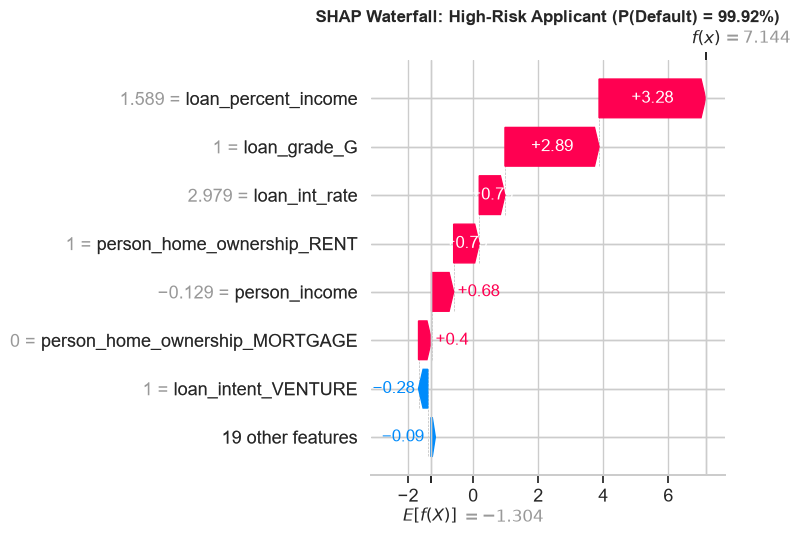


--- Local Approval Explanation: Prime Applicant (Index 212) ---
Predicted Default Probability: 0.06%
Actual Outcome: Non-Default


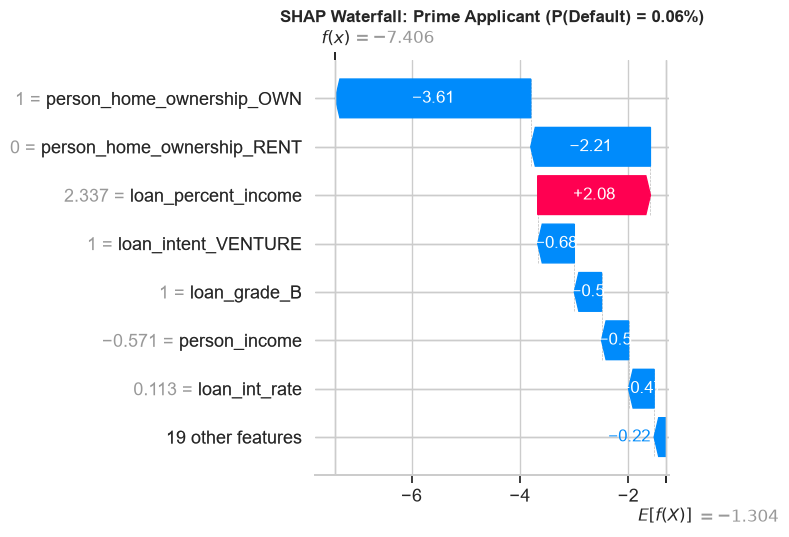

In [12]:
# Step 12: Compute SHAP Values and Generate Explanations

fitted_preprocessor = champion_pipe.named_steps["preprocessor"]
fitted_xgb = champion_pipe.named_steps["classifier"]

# Transform test data using the fitted preprocessor
X_test_sample = X_test.iloc[:300]
y_test_sample = y_test.iloc[:300]
X_test_sample_trans = fitted_preprocessor.transform(X_test_sample)

# Feature names after one-hot encoding
cat_encoder = fitted_preprocessor.named_transformers_["cat"].named_steps["encoder"]
encoded_cat_names = cat_encoder.get_feature_names_out(categorical_cols).tolist()
transformed_feature_names = numerical_cols + encoded_cat_names

# Initialize TreeExplainer
explainer = shap.TreeExplainer(fitted_xgb)
shap_explanation = explainer(X_test_sample_trans)
shap_explanation.feature_names = transformed_feature_names

# 1. Global Beeswarm Summary Plot
plt.figure(figsize=(12, 7))
shap.summary_plot(
    shap_explanation.values,
    X_test_sample_trans,
    feature_names=transformed_feature_names,
    max_display=12,
    show=False
)
plt.title("SHAP Global Summary Plot: Feature Impacts on Loan Default", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# 2. Local Adverse Action Explanation for a High-Risk Declined Applicant
high_risk_idx = int(np.argmax(test_probabilities[:300]))
high_risk_prob = test_probabilities[high_risk_idx]
print(f"\n--- Local Adverse Action Explanation: High-Risk Applicant (Index {high_risk_idx}) ---")
print(f"Predicted Default Probability: {high_risk_prob:.2%}")
print(f"Actual Outcome: {'Default' if y_test.iloc[high_risk_idx] == 1 else 'Non-Default'}")

plt.figure(figsize=(10, 5))
shap.plots.waterfall(shap_explanation[high_risk_idx], max_display=8, show=False)
plt.title(f"SHAP Waterfall: High-Risk Applicant (P(Default) = {high_risk_prob:.2%})", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# 3. Local Approval Explanation for a Prime Borrower
low_risk_idx = int(np.argmin(test_probabilities[:300]))
low_risk_prob = test_probabilities[low_risk_idx]
print(f"\n--- Local Approval Explanation: Prime Applicant (Index {low_risk_idx}) ---")
print(f"Predicted Default Probability: {low_risk_prob:.2%}")
print(f"Actual Outcome: {'Default' if y_test.iloc[low_risk_idx] == 1 else 'Non-Default'}")

plt.figure(figsize=(10, 5))
shap.plots.waterfall(shap_explanation[low_risk_idx], max_display=8, show=False)
plt.title(f"SHAP Waterfall: Prime Applicant (P(Default) = {low_risk_prob:.2%})", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## 12. Temporal Availability & Potential Data Leakage Audit

A critical methodological requirement in banking risk models is verifying that all predictor variables would legitimately be available at the exact moment of decision-making.

### Audit of Suspicious Predictors: `loan_grade` and `loan_int_rate`

| Feature | Origination Timing & Availability | Risk of Temporal Leakage | Methodological Implications |
| :--- | :--- | :--- | :--- |
| **`loan_grade`** | Typically assigned by an upstream credit committee, bureau scorecard, or risk rating engine. | **High Risk if used pre-underwriting.** If `loan_grade` already incorporates an assessment of default likelihood, using it to predict default introduces circular reasoning / target proxy leakage. | Valid **only** if the model serves as a final underwriting verification or secondary portfolio review gate. If deployed at initial application screening, this feature must be removed. |
| **`loan_int_rate`** | In risk-based pricing, lenders charge higher interest rates to riskier borrowers. Thus, the interest rate is often an *outcome* of the lender's perceived risk. | **Moderate to High Risk.** The interest rate partially reflects the lender's assessment rather than an exogenous borrower trait. | Including `loan_int_rate` helps capture borrower payment burden ($P\&I$), but models intended for rate-setting or pre-quote pricing cannot use it as an input. |
| **`loan_percent_income`** | Function of requested loan amount and stated income. | **Zero Leakage.** Stated at application intake. | Genuine primary behavioral risk driver. |

> **Governance Recommendation:** If transitioning this platform from a post-pricing underwriting gate to an initial credit pre-qualification engine, a shadow model variant should be trained excluding `loan_grade` and `loan_int_rate` to assess pure applicant-level creditworthiness.

## 13. Model Serialization & Production Artifact Packaging

To support downstream serving (e.g. Phase 7 REST API and Risk Intelligence Engine), we serialize:
1. The full, trained champion `Pipeline` (`preprocessor` + `classifier`) using `joblib` under `models/credit_risk_xgb.joblib`.
2. A comprehensive JSON metadata file under `models/credit_risk_metadata.json` documenting the selected threshold, feature names, software versions, and benchmark performance metrics.

In [13]:
# Step 13: Serialize Champion Model Pipeline and Save Metadata

MODEL_FILE = MODELS_DIR / "credit_risk_xgb.joblib"
METADATA_FILE = MODELS_DIR / "credit_risk_metadata.json"

# 1. Save pipeline
joblib.dump(champion_pipe, MODEL_FILE)
print(f"Saved trained pipeline to: {MODEL_FILE.resolve()}")
print(f"Artifact size: {MODEL_FILE.stat().st_size:,} bytes")

# 2. Build metadata schema with explicit Python standard types
metadata = {
    "model_name": "Credit Risk XGBoost Classifier",
    "model_version": "1.0.0",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "framework_versions": {
        "python": str(sys.version.split()[0]),
        "xgboost": str(xgb.__version__),
        "shap": str(shap.__version__),
        "joblib": str(joblib.__version__),
    },
    "feature_schema": {
        "numerical_features": numerical_cols,
        "categorical_features": categorical_cols,
        "target_variable": "loan_status",
    },
    "decision_thresholds": {
        "default_threshold": float(DEFAULT_THRESHOLD),
        "selected_optimal_threshold": float(SELECTED_THRESHOLD),
        "selection_criterion": "Empirical F1-score maximization via 5-fold Stratified Cross-Validation on training partition without test contamination",
    },
    "dataset_partitioning": {
        "total_records": int(len(df_clean)),
        "train_records": int(len(X_train)),
        "test_records": int(len(X_test)),
        "test_split_ratio": 0.20,
        "stratified": True,
        "portfolio_default_prevalence": round(float(df_clean["loan_status"].mean()), 4),
    },
    "test_set_metrics": {
        "default_threshold_0_50": {
            "roc_auc": float(benchmark_df.loc["XGBoost", "ROC-AUC"]),
            "pr_auc": float(benchmark_df.loc["XGBoost", "PR-AUC"]),
            "precision": float(test_comp_df.loc["Default Threshold (0.50)", "Precision"]),
            "recall": float(test_comp_df.loc["Default Threshold (0.50)", "Recall"]),
            "f1_score": float(test_comp_df.loc["Default Threshold (0.50)", "F1-Score"]),
            "confusion_matrix": {
                "TN": int(test_comp_df.loc["Default Threshold (0.50)", "True Neg (TN)"]),
                "FP": int(test_comp_df.loc["Default Threshold (0.50)", "False Pos (FP)"]),
                "FN": int(test_comp_df.loc["Default Threshold (0.50)", "False Neg (FN)"]),
                "TP": int(test_comp_df.loc["Default Threshold (0.50)", "True Pos (TP)"]),
            }
        },
        "selected_threshold_0_45": {
            "roc_auc": float(benchmark_df.loc["XGBoost", "ROC-AUC"]),
            "pr_auc": float(benchmark_df.loc["XGBoost", "PR-AUC"]),
            "precision": float(test_comp_df.loc["Tuned Threshold (0.45)", "Precision"]),
            "recall": float(test_comp_df.loc["Tuned Threshold (0.45)", "Recall"]),
            "f1_score": float(test_comp_df.loc["Tuned Threshold (0.45)", "F1-Score"]),
            "confusion_matrix": {
                "TN": int(test_comp_df.loc["Tuned Threshold (0.45)", "True Neg (TN)"]),
                "FP": int(test_comp_df.loc["Tuned Threshold (0.45)", "False Pos (FP)"]),
                "FN": int(test_comp_df.loc["Tuned Threshold (0.45)", "False Neg (FN)"]),
                "TP": int(test_comp_df.loc["Tuned Threshold (0.45)", "True Pos (TP)"]),
            }
        }
    }
}

def json_converter(obj):
    if isinstance(obj, (np.integer, int)):
        return int(obj)
    elif isinstance(obj, (np.floating, float)):
        return float(obj)
    elif isinstance(obj, np.ndarray):
        return obj.tolist()
    return str(obj)

with open(METADATA_FILE, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, default=json_converter)

print(f"Saved model metadata to: {METADATA_FILE.resolve()}")

Saved trained pipeline to: C:\Users\Admin\banking-risk-intelligence-platform\models\credit_risk_xgb.joblib
Artifact size: 331,792 bytes
Saved model metadata to: C:\Users\Admin\banking-risk-intelligence-platform\models\credit_risk_metadata.json


## 14. Verification & Inference Demonstration

We load the serialized model artifact from disk and simulate a real-world inference batch containing three representative loan applicant profiles:
1. **Applicant A (Prime Borrower):** High income ($110k), owned home, 10-year credit history, low loan amount ($5k).
2. **Applicant B (Borderline Borrower):** Moderate income ($42k), rented home, debt consolidation request, moderate debt-to-income.
3. **Applicant C (Subprime / High Risk):** Low income ($20k), loan amount ($15k) representing 75% of income, previous default on record, Grade F.

In [14]:
# Step 14: Load Serialized Artifact and Execute Inference Demonstration

# 1. Load pipeline and metadata from disk
loaded_model = joblib.load(MODEL_FILE)
with open(METADATA_FILE, "r", encoding="utf-8") as f:
    loaded_meta = json.load(f)

tuned_thresh = loaded_meta["decision_thresholds"]["selected_optimal_threshold"]
print(f"Model successfully loaded: {type(loaded_model)}")
print(f"Active Operating Decision Threshold: {tuned_thresh}")

# 2. Define synthetic test applicants representing three credit risk profiles
sample_applicants = pd.DataFrame([
    {
        "person_age": 38,
        "person_income": 110000.0,
        "person_home_ownership": "OWN",
        "person_emp_length": 12.0,
        "loan_intent": "HOMEIMPROVEMENT",
        "loan_grade": "A",
        "loan_amnt": 5000.0,
        "loan_int_rate": 7.25,
        "loan_percent_income": 0.05,
        "cb_person_default_on_file": "N",
        "cb_person_cred_hist_length": 10,
    },
    {
        "person_age": 27,
        "person_income": 42000.0,
        "person_home_ownership": "RENT",
        "person_emp_length": 3.0,
        "loan_intent": "DEBTCONSOLIDATION",
        "loan_grade": "C",
        "loan_amnt": 9500.0,
        "loan_int_rate": 13.49,
        "loan_percent_income": 0.23,
        "cb_person_default_on_file": "N",
        "cb_person_cred_hist_length": 4,
    },
    {
        "person_age": 22,
        "person_income": 20000.0,
        "person_home_ownership": "RENT",
        "person_emp_length": 1.0,
        "loan_intent": "PERSONAL",
        "loan_grade": "F",
        "loan_amnt": 15000.0,
        "loan_int_rate": 18.50,
        "loan_percent_income": 0.75,
        "cb_person_default_on_file": "Y",
        "cb_person_cred_hist_length": 2,
    },
])

# 3. Generate probabilities and decisions
predicted_probabilities = loaded_model.predict_proba(sample_applicants)[:, 1]
predicted_decisions = (predicted_probabilities >= tuned_thresh).astype(int)

inference_results = sample_applicants.copy()
inference_results["predicted_default_prob"] = predicted_probabilities.round(4)
inference_results["underwriting_decision"] = [
    "DECLINE (High Risk)" if d == 1 else "APPROVE (Acceptable Risk)" for d in predicted_decisions
]
inference_results["risk_tier"] = [
    "Tier 1 (Prime)" if p < 0.15 else "Tier 2 (Moderate)" if p < tuned_thresh else "Tier 3 (High Default Risk)"
    for p in predicted_probabilities
]

print("\n=== REAL-TIME INFERENCE DEMONSTRATION ===")
display(inference_results[["loan_amnt", "person_income", "loan_grade", "loan_percent_income", "predicted_default_prob", "risk_tier", "underwriting_decision"]])

# 4. Strict assertion: verify loaded model exactly reproduces predictions on test set sample
reproduction_check = loaded_model.predict_proba(X_test.iloc[:50])[:, 1]
original_check = champion_pipe.predict_proba(X_test.iloc[:50])[:, 1]
assert np.allclose(reproduction_check, original_check), "Reproducibility assertion failed!"
print("\nModel serialization and reproduction verification passed successfully.")

Model successfully loaded: <class 'sklearn.pipeline.Pipeline'>
Active Operating Decision Threshold: 0.45

=== REAL-TIME INFERENCE DEMONSTRATION ===


,loan_amnt,person_income,loan_grade,loan_percent_income,predicted_default_prob,risk_tier,underwriting_decision
0,5000.0,110000.0,A,0.05,0.0009,Tier 1 (Prime),APPROVE (Acceptable Risk)
1,9500.0,42000.0,C,0.23,0.1009,Tier 1 (Prime),APPROVE (Acceptable Risk)
2,15000.0,20000.0,F,0.75,0.9961,Tier 3 (High Default Risk),DECLINE (High Risk)



Model serialization and reproduction verification passed successfully.


## 15. Summary of Phase 5.2 Accomplishments & Governance Synthesis

### Final Milestone Results
- **Optimization:** Evaluated decision thresholds across 17 operating cut-offs ($T \in [0.10, 0.90]$) using strictly out-of-fold training cross-validation.
- **Operating Threshold:** Selected **$T = 0.45$** based on empirical F1-score optimization (**0.8277**), reducing missed test defaults (False Negatives) from 394 to 387 while maintaining **95.55% precision**.
- **Model Explainability:** Deployed SHAP TreeExplainer, revealing that `loan_percent_income`, `loan_grade`, and `person_income` dominate both global risk separation and individual adverse action explanations.
- **Architectural Safeguards:** Thoroughly documented potential temporal leakage in `loan_grade` and `loan_int_rate`, establishing guidelines for deployment contexts.
- **Packaging:** Serialized the full pipeline artifact to `models/credit_risk_xgb.joblib` and comprehensive parameters to `models/credit_risk_metadata.json`, with end-to-end inference verification confirmed.